# 12 · Final comparison, error analysis and protocol ablation
**Owner:** shared

All numbers below come from the saved runs of notebooks 08–11 (same split, same metrics, test split scored once per selected configuration).

In [1]:
%matplotlib inline
import os, sys
os.environ.setdefault("KERAS_BACKEND", "torch")   # Keras 3 backend used for our runs (CPU); "tensorflow" also works
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))        # make the project's src/ package importable

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
from IPython.display import Image, display
from src import config, data_pipeline as dp, models, features, training

keras.utils.set_random_seed(config.SEED)
print("Keras", keras.__version__, "| backend:", keras.backend.backend())
from src import experiments as E, evaluation as ev, finetune as F, gradcam as G
RERUN = False    # True = retrain everything here; False = load the saved runs produced by the same code
                 # (scripts/run_heads.py, scripts/run_finetune.py), which take hours on a CPU

Keras 3.15.1 | backend: torch


In [2]:
from src.analysis import build_all
res = build_all()          # writes results/final/*.json|csv and the figures
res["comparison"]

,accuracy,precision,recall,specificity,f1,balanced_accuracy,roc_auc,FN,FP,seeds
MLP baseline,94.10 ± 1.21,96.59 ± 1.98,95.64 ± 0.80,89.20 ± 6.56,96.10 ± 0.75,92.42 ± 3.00,0.969 ± 0.022,53.7 ± 9.9,42.0 ± 25.5,3
VGG16 (fine-tuned),97.41 ± 0.88,98.64 ± 0.32,97.94 ± 1.44,95.72 ± 1.07,98.28 ± 0.59,96.83 ± 0.34,0.997 ± 0.001,25.3 ± 17.8,16.7 ± 4.2,3
ResNet50 (fine-tuned),98.21 ± 0.43,99.10 ± 0.15,98.54 ± 0.49,97.18 ± 0.44,98.82 ± 0.29,97.85 ± 0.40,0.997 ± 0.000,18.0 ± 6.1,11.0 ± 1.7,3
Hybrid VGG16–ResNet50 (fine-tuned),98.03 ± 0.41,99.04 ± 0.23,98.35 ± 0.61,97.00 ± 0.74,98.69 ± 0.27,97.67 ± 0.34,0.998 ± 0.000,20.3 ± 7.5,11.7 ± 2.9,3


In [3]:
res["comparison_variants"]

,val balanced acc,test accuracy,test recall,test specificity,test F1,test ROC-AUC,trainable params,train time / run (min),seeds
VGG16 · frozen,94.62 ± 2.26,96.79 ± 0.27,97.35 ± 0.05,95.03 ± 0.97,97.88 ± 0.17,0.994 ± 0.002,"131,842",0.2,3
VGG16 · finetuned,96.31 ± 1.57,97.41 ± 0.88,97.94 ± 1.44,95.72 ± 1.07,98.28 ± 0.59,0.997 ± 0.001,"7,211,266",25.9,3
ResNet50 · frozen,97.27 ± 0.54,97.90 ± 0.25,98.73 ± 0.39,95.29 ± 0.83,98.62 ± 0.17,0.997 ± 0.000,"262,530",0.3,3
ResNet50 · finetuned,97.95 ± 0.05,98.21 ± 0.43,98.54 ± 0.49,97.18 ± 0.44,98.82 ± 0.29,0.997 ± 0.000,"15,216,002",19.2,3
Hybrid VGG16–ResNet50 · frozen,97.22 ± 0.79,97.88 ± 0.22,98.16 ± 0.52,97.00 ± 0.90,98.60 ± 0.15,0.998 ± 0.000,"328,066",0.3,3
Hybrid VGG16–ResNet50 · finetuned,97.78 ± 0.98,98.03 ± 0.41,98.35 ± 0.61,97.00 ± 0.74,98.69 ± 0.27,0.998 ± 0.000,"22,360,962",33.4,3


## Paired significance (McNemar, seed 42, test split)

In [4]:
res["mcnemar"]

,A,B,"A right, B wrong","A wrong, B right",p-value (exact)
0,MLP baseline,VGG16,29,64,0.0004
1,MLP baseline,ResNet50,8,70,0.0000
2,MLP baseline,Hybrid VGG16–ResNet50,19,68,0.0000
3,VGG16,ResNet50,8,35,0.0000
4,VGG16,Hybrid VGG16–ResNet50,13,27,0.0385
5,ResNet50,Hybrid VGG16–ResNet50,18,5,0.0106


## ROC curves

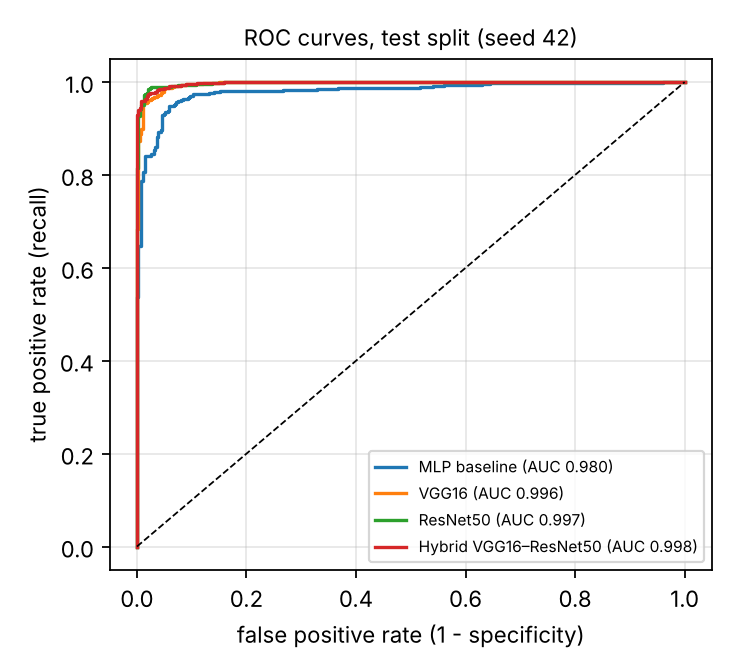

In [5]:
display(Image(str(config.FIG_DIR / "final_roc.png"), width=480))

## Error analysis by tumor subtype (missed tumors) and by source of false alarms

In [6]:
res["errors_by_subtype"]

,glioma missed,meningioma missed,pituitary missed,no-tumor false alarms,"bootstrap 95% CI, balanced acc."
MLP baseline,22 / 412,43 / 411,0 / 408,23 / 389,"[0.930, 0.957]"
VGG16,10 / 412,26 / 411,5 / 408,12 / 389,"[0.958, 0.978]"
ResNet50,2 / 412,11 / 411,1 / 408,12 / 389,"[0.970, 0.987]"
Hybrid VGG16–ResNet50,6 / 412,18 / 411,5 / 408,10 / 389,"[0.966, 0.984]"


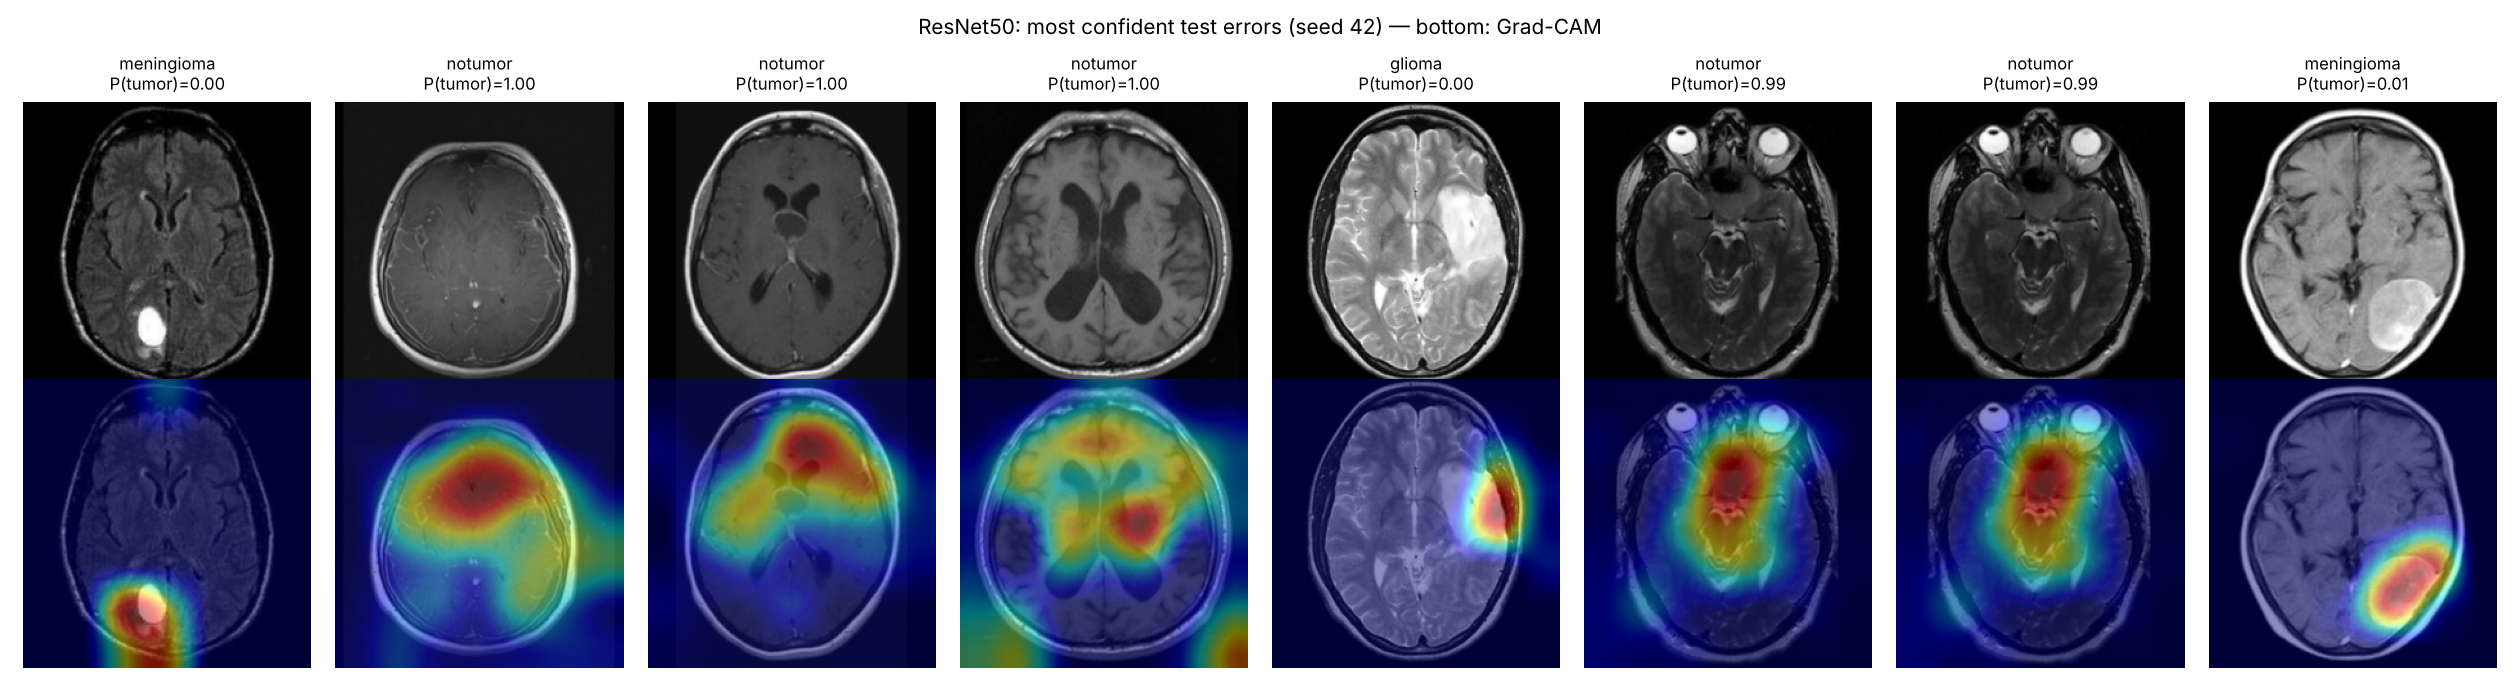

In [7]:
display(Image(str(config.FIG_DIR / "final_errors_gallery.png"), width=900))

## Protocol ablation: how much of the interim score came from the shortcut and from near-duplicates?

In [8]:
res["ablation"]

val accuracy  \
protocol                               model                                 
P0 original split, uncropped (interim) MLP baseline           96.96 ± 0.40   
                                       VGG16                  98.84 ± 0.11   
                                       ResNet50               98.68 ± 0.27   
                                       Hybrid VGG16–ResNet50  98.90 ± 0.33   
P1 original split, cropped             MLP baseline           96.90 ± 0.23   
                                       VGG16                  98.59 ± 0.05   
                                       ResNet50               98.65 ± 0.19   
                                       Hybrid VGG16–ResNet50  98.44 ± 0.32   
P2 leak-free split, cropped (final)    MLP baseline           92.04 ± 1.00   
                                       VGG16                  96.61 ± 1.02   
                                       ResNet50               98.21 ± 0.05   
                                       Hybrid VGG16–ResNet50  98.00 ± 0.19   

                                                             test accuracy  \
protocol                               model                                 
P0 original split, uncropped (interim) MLP baseline           93.12 ± 1.33   
                                       VGG16                  97.31 ± 0.57   
                                       ResNet50               97.50 ± 0.85   
                                       Hybrid VGG16–ResNet50  97.33 ± 0.93   
P1 original split, cropped             MLP baseline           94.07 ± 0.55   
                                       VGG16                  98.07 ± 0.40   
                                       ResNet50               97.48 ± 0.40   
                                       Hybrid VGG16–ResNet50  97.35 ± 1.11   
P2 leak-free split, cropped (final)    MLP baseline           94.10 ± 1.21   
                                       VGG16                  96.79 ± 0.27   
                                       ResNet50               97.90 ± 0.25   
                                       Hybrid VGG16–ResNet50  97.88 ± 0.22   

                                                             test balanced acc  \
protocol                               model                                     
P0 original split, uncropped (interim) MLP baseline               94.35 ± 1.28   
                                       VGG16                      98.20 ± 0.38   
                                       ResNet50                   98.27 ± 0.60   
                                       Hybrid VGG16–ResNet50      98.16 ± 0.64   
P1 original split, cropped             MLP baseline               95.29 ± 0.52   
                                       VGG16                      98.68 ± 0.32   
                                       ResNet50                   98.23 ± 0.38   
                                       Hybrid VGG16–ResNet50      98.04 ± 0.81   
P2 leak-free split, cropped (final)    MLP baseline               92.42 ± 3.00   
                                       VGG16                      96.19 ± 0.51   
                                       ResNet50                   97.00 ± 0.35   
                                       Hybrid VGG16–ResNet50      97.58 ± 0.24   

                                                             test specificity  \
protocol                               model                                    
P0 original split, uncropped (interim) MLP baseline              96.83 ± 1.38   
                                       VGG16                    100.00 ± 0.00   
                                       ResNet50                  99.83 ± 0.14   
                                       Hybrid VGG16–ResNet50     99.83 ± 0.14   
P1 original split, cropped             MLP baseline              97.75 ± 1.00   
                                       VGG16                     99.92 ± 0.14   
                                       ResNet50                  99.75 ± 0.43  

In [9]:
res["leak_vs_clean"]

tumour images missed  \
model (seed 42, frozen) test subset                                            
MLP baseline            has near-duplicate in train/val           697     44   
                        no near-duplicate                         487     43   
VGG16                   has near-duplicate in train/val           697     12   
                        no near-duplicate                         487     25   
ResNet50                has near-duplicate in train/val           697     19   
                        no near-duplicate                         487     23   
Hybrid VGG16–ResNet50   has near-duplicate in train/val           697     29   
                        no near-duplicate                         487     27   

                                                        tumour recall %  \
model (seed 42, frozen) test subset                                       
MLP baseline            has near-duplicate in train/val           93.69   
                        no near-duplicate                         91.17   
VGG16                   has near-duplicate in train/val           98.28   
                        no near-duplicate                         94.87   
ResNet50                has near-duplicate in train/val           97.27   
                        no near-duplicate                         95.28   
Hybrid VGG16–ResNet50   has near-duplicate in train/val           95.84   
                        no near-duplicate                         94.46   

                                                        no-tumour images  
model (seed 42, frozen) test subset                                       
MLP baseline            has near-duplicate in train/val              390  
                        no near-duplicate                             10  
VGG16                   has near-duplicate in train/val              390  
                        no near-duplicate                             10  
ResNet50                has near-duplicate in train/val              390  
                        no near-duplicate                             10  
Hybrid VGG16–ResNet50   has near-duplicate in train/val              390  
                        no near-duplicate                             10